Chạy trên **máy local** (không cần tải file thủ công: notebook tự clone 4 nhánh từ GitHub và sinh `output/`).

- Cần Internet để `git clone` từ GitHub. Mở notebook bằng kernel `.venv` (đã có sẵn các thư viện đã ghim). Thư mục làm việc là `run_local/` cạnh notebook.

# Nhóm 10 – Dự đoán tái nhập viện ở bệnh nhân đái tháo đường (Diabetes 130-US)
**Notebook tổng hợp:** chạy **script của từng thành viên, lấy trực tiếp từ nhánh của người đó**, theo thứ tự từ trên xuống. Các bước nối với nhau bằng file trong `output/`: output của bước trước là input của bước sau. `Run All` là chạy cả pipeline.

| Bước | Task | Người | Script (nhánh) | Đọc | Ghi (`output/`) |
|---|---|---|---|---|---|
| 01 | Bỏ thuộc tính định danh | Dũng | `src/01_explore_and_drop_ids.py` (Dung) | `data/diabetic_data.csv` | `step1.csv`, `step1_patient_nbr.csv` |
| 02 | Thống kê khuyết, bỏ cột khuyết > 50% | Sơn | `src/02_missing_stats_and_filter.py` (Son) | `step1.csv` | `step2.csv`, `missing_rate.csv` |
| 03 | Bỏ dòng khuyết < 2%, tạo nhãn, chia 80/20 | Chiến | `src/03_data_preprocessing_splitting.py` (Chien) | `step2.csv`, `step1_patient_nbr.csv` | `train.csv`, `test.csv` |
| 04 | One-Hot (fit trên train) | Dũng | `src/04_one_hot_encoding.py` (Dung) | `train.csv`, `test.csv` | `X_train_onehot.npz`, `X_test_onehot.npz`, `onehot_columns.txt`, `y_train.csv`, `y_test.csv` |
| 05 | PCA 60 thành phần | Sơn | `src/05_pca.py` (Son) | `X_*_onehot.npz`, `onehot_columns.txt` | `X_train_pca.npy`, `X_test_pca.npy`, `pca_eigenvalues.npy`, `pca_components.npy`, `pca_feature_names.txt` |
| 06 | Chuẩn hóa sau PCA, scree plot, top 5 vector riêng | Chiến | `src/06_feature_scaling_pca_analysis.py` (Chien) | `X_*_pca.npy`, `pca_*` | `X_train_pca_scaled.npy`, `X_test_pca_scaled.npy`, `eigenvalues.png` |
| 07a | k-NN tự cài, PCA chưa vs đã chuẩn hóa | Dũng | `src/07a_knn.py` (Dung) | `X_*_pca*.npy`, `y_*.csv` | `knn_results.csv`, `knn_k_curve.png` |
| 07b | Softmax Regression tự cài, chưa vs đã chuẩn hóa | Dũng | `src/07b_softmax_regression.py` (Dung) | `X_*_pca*.npy`, `y_*.csv` | `softmax_results.csv`, `softmax_loss.png` |
| 08a | Decision Tree, tinh chỉnh max_depth | Sơn | `src/08a_decision_tree.py` (Son) | `X_*_pca.npy`, `y_*.csv` | `dt_results.csv`, `dt_depth_curve.png`, `pred_multi_dt.npy`, `proba_{val,test}_dt.npy` |
| 08b | Random Forest, tinh chỉnh max_depth, n_estimators | Sơn | `src/08b_random_forest.py` (Son) | `X_*_pca.npy`, `y_*.csv` | `rf_results.csv`, `rf_depth_curve.png`, `pred_multi_rf.npy`, `proba_{val,test}_rf.npy` |
| 09a | MLP 120-60-20, ReLU | Chiến | `src/09a_mlp.py` (Chien) | `X_*_pca_scaled.npy`, `y_*.csv` | `mlp_results.csv`, `mlp_alpha_curve.png`, `mlp_loss.png`, `pred_multi_mlp.npy`, `proba_{val,test}_mlp.npy` |
| 09b | Ensemble trọng số AUC (DT, RF, MLP, LR) | Chiến | `src/09b_ensemble.py` (Chien) | `proba_{val,test}_*.npy` | `ensemble_weights.csv`, `ensemble_results.csv`, `proba_test_ensemble.npy` |
| 10 | Test Accuracy multi-class, ma trận nhầm lẫn | Dũng | `src/10_evaluation.py` (Dung) | `pred_*.npy`, `y_test.csv` | `accuracy_summary.csv`, `confusion_*.csv`, `confusion_matrices.png` |
| 11 | Test Accuracy nhị phân, ROC/AUC | Sơn | `src/11_binary_evaluation.py` (Son) | `proba_test_*.npy`, `y_test.csv` | `binary_summary.csv`, `roc_curves.png`, `confusion_binary.png` |
| 12 | Class Imbalance; RF trên One-Hot chưa PCA | Chiến | `src/12_imbalance_and_rf_raw.py` (Chien) | `y_*.csv`, `X_*_onehot.npz`, `rf_results.csv`, `proba_*_rf.npy` | `imbalance_*.csv`, `rf_raw_*.csv`, `rf_raw_importance.png` |

**Quy ước:** mọi script chạy từ thư mục gốc dự án, đọc/ghi đúng tên file trong bảng; không đổi tên khi chưa báo cả nhóm. Các bước học từ dữ liệu chỉ fit trên train. `random_state = 42`. Muốn sửa một bước thì sửa script trên nhánh của mình rồi push, chạy lại notebook là cập nhật.

## 0. Cài đặt
Clone cả bốn nhánh (`main`, `Dung`, `Son`, `Chien`) vào `run_local/branches/`. Thư mục làm việc là `branches/main` (có dữ liệu gốc `data/diabetic_data.csv`); script của từng người được gọi qua `../Dung/src/...`, `../Son/src/...`, `../Chien/src/...`, nên tất cả cùng đọc/ghi một thư mục `output/`.

Phiên bản thư viện được ghim (`scikit-learn==1.6.1`, `pandas==2.2.3`, `numpy==2.4.6`): cách chia train/test ở bước 03 phụ thuộc phiên bản scikit-learn, khác phiên bản sẽ ra tập train/test khác (79.726 / 20.518 dòng với bản 1.6.1). Kiểm tra dòng in phiên bản ở cuối cell bên dưới trước khi chạy tiếp.


In [1]:
REPO = "https://github.com/chiensondung/HCMUT-AnIntroductiontoMachineLearningandApplication-Project.git"
import os, shutil, subprocess
from pathlib import Path

BASE = Path.cwd() / "run_local"
BASE.mkdir(parents=True, exist_ok=True)

shutil.rmtree(BASE / "branches", ignore_errors=True)
for b in ["main", "Dung", "Son", "Chien"]:
    subprocess.run(["git", "clone", "-q", "-b", b, REPO, str(BASE / "branches" / b)], check=True)
    print(subprocess.run(["git", "-C", str(BASE / "branches" / b), "log", "-1", "--format=%h %an %ad %s", "--date=short"],
                         capture_output=True, text=True).stdout.strip().join([f"{b}: ", ""]))

os.chdir(BASE / "branches" / "main")
print("Thư mục làm việc:", Path.cwd())
%pip -q install -r ../Dung/requirements.txt -r ../Son/requirements.txt -r ../Chien/requirements.txt
%pip -q install scikit-learn==1.6.1 pandas==2.2.3 numpy==2.4.6
import sklearn, pandas, numpy; print('sklearn', sklearn.__version__, '| pandas', pandas.__version__, '| numpy', numpy.__version__)

main: 6ef451d Trịnh Hoàng Dũng 2026-11-18 Được tạo bằng Colab
Dung: 1d4c9a7 hdung274520 2026-11-18 Cập nhật số liệu PCA sau khi bước 05 loại 2 cột hằng số
Son: efc302f chiensondung 2026-11-18 Thêm mục 3.4 kết quả nhị phân và bổ sung tên mô hình ở bước 11
Chien: 87e0199 Ho Ba Chien 2026-11-18 Track output/*.npy (PCA matrices, predictions, probabilities); keep ignoring *.npz
Thư mục làm việc: /home/hdung274520/Study/261/Máy học Cơ bản và Ứng dụng/Dung/run_local/branches/main
/home/hdung274520/Study/261/Máy học Cơ bản và Ứng dụng/Dung/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/home/hdung274520/Study/261/Máy học Cơ bản và Ứng dụng/Dung/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
sklearn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


## Giai đoạn 1: Khảo sát và xử lý dữ liệu khuyết

### Bước 01: Bỏ thuộc tính định danh *(Dũng)*

In [2]:
!python ../Dung/src/01_explore_and_drop_ids.py

Kích thước gốc: (101766, 50)

Khảo sát cột định danh:
   encounter_id  patient_nbr payer_code
0       2278392      8222157        NaN
1        149190     55629189        NaN
2         64410     86047875        NaN
3        500364     82442376        NaN
4         16680     42519267        NaN
Số giá trị khác nhau:
 encounter_id    101766
patient_nbr      71518
payer_code          17
dtype: int64
Tỉ lệ khuyết (%):
 encounter_id     0.00
patient_nbr      0.00
payer_code      39.56
dtype: float64

Kích thước sau khi bỏ định danh: (101766, 47)


### Bước 02: Thống kê khuyết, bỏ cột khuyết > 50% *(Sơn)*

In [3]:
!python ../Son/src/02_missing_stats_and_filter.py

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

Bỏ (khuyết >50%): ['weight', 'max_glu_serum', 'A1Cresult']
Kích thước: (101766, 44)


### Bước 03: Bỏ dòng khuyết < 2%, tạo nhãn, chia train/test 80/20 *(Chiến)*

In [4]:
!python ../Chien/src/03_data_preprocessing_splitting.py

Kích thước step2: (101766, 44)
Cột khuyết <2%: ['diag_1', 'diag_2', 'diag_3'] | xóa 1522 dòng
Kích thước sau xử lý: (100244, 45) | train: 79726 | test: 20518
train {'NO': 0.5381, '>30': 0.3503, '<30': 0.1116} | y_bin=1: 0.4619
test {'NO': 0.5323, '>30': 0.353, '<30': 0.1147} | y_bin=1: 0.4677
Còn khuyết: {'race': 2191, 'medical_specialty': 49482}


## Giai đoạn 2: One-Hot, PCA, chuẩn hóa

### Bước 04: One-Hot Encoding *(Dũng)*

In [5]:
!python ../Dung/src/04_one_hot_encoding.py

Train: (79726, 45) | Test: (20518, 45)
Số biến phân loại: 35
Biến số giữ nguyên: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
diag_3                      761
diag_2                      716
diag_1                      697
medical_specialty            71
discharge_disposition_id     26
admission_source_id          17
age                          10
admission_type_id             8
dtype: int64

Số cột One-Hot: 2388
diag_1 -> 697 cột
diag_2 -> 716 cột
diag_3 -> 761 cột
Mỗi dòng train có đúng 35 số 1: True

Đã lưu X_train: (79726, 2396) | X_test: (20518, 2396)


### Bước 05: PCA 60 thành phần trên ma trận tương quan *(Sơn)*

In [6]:
!python ../Son/src/05_pca.py

One-Hot + số (train): (79726, 2396) | (test): (20518, 2396)
Bỏ 2 cột phương sai 0 trên train: ['examide_No', 'citoglipton_No']
Số chiều sau khi bỏ cột phương sai 0: 2394

Tỉ lệ phương sai giải thích bởi 60 thành phần: 0.0555
Số thành phần cần để đạt 95%: 2115
Kiểm tra trên mẫu 8000 dòng: lệch tối đa trị riêng so với sklearn.PCA = 1.88e-13

Đã lưu Z_train: (79726, 60) | Z_test: (20518, 60)


### Bước 06: Chuẩn hóa sau PCA, biểu đồ Eigenvalues, top 5 vector riêng *(Chiến)*

In [7]:
!python ../Chien/src/06_feature_scaling_pca_analysis.py

X_train_pca: (79726, 60) | X_test_pca: (20518, 60) | components: (2394, 60)
60 thành phần giải thích 5.55% phương sai

PC1: eigenvalue = 4.8591, giải thích 0.20% phương sai
       dac_trung  trong_so
       change_No    0.3839
       change_Ch   -0.3839
  diabetesMed_No    0.3618
 diabetesMed_Yes   -0.3618
      insulin_No    0.2756
    metformin_No    0.1904
 num_medications   -0.1854
metformin_Steady   -0.1741
      insulin_Up   -0.1423
    insulin_Down   -0.1418

PC2: eigenvalue = 4.3718, giải thích 0.18% phương sai
                dac_trung  trong_so
    admission_source_id_7    0.3591
      admission_type_id_1    0.3492
    admission_source_id_1   -0.3417
      admission_type_id_3   -0.3065
       num_lab_procedures    0.1863
         number_diagnoses    0.1609
           num_procedures   -0.1554
medical_specialty_Missing    0.1276
               diag_1_715   -0.1266
               diag_1_414   -0.1182

PC3: eigenvalue = 3.4859, giải thích 0.15% phương sai
                 dac_tru

### Kết quả Giai đoạn 2

total 145404
drwxrwxr-x 2 hdung274520 hdung274520     4096 Nov 18 20:01 .
drwxrwxr-x 5 hdung274520 hdung274520     4096 Nov 18 20:00 ..
-rw-rw-r-- 1 hdung274520 hdung274520   514538 Nov 18 20:00 X_test_onehot.npz
-rw-rw-r-- 1 hdung274520 hdung274520  9848768 Nov 18 20:01 X_test_pca.npy
-rw-rw-r-- 1 hdung274520 hdung274520  9848768 Nov 18 20:01 X_test_pca_scaled.npy
-rw-rw-r-- 1 hdung274520 hdung274520  1997542 Nov 18 20:00 X_train_onehot.npz
-rw-rw-r-- 1 hdung274520 hdung274520 38268608 Nov 18 20:01 X_train_pca.npy
-rw-rw-r-- 1 hdung274520 hdung274520 38268608 Nov 18 20:01 X_train_pca_scaled.npy
-rw-rw-r-- 1 hdung274520 hdung274520    74080 Nov 18 20:01 eigenvalues.csv
-rw-rw-r-- 1 hdung274520 hdung274520    93451 Nov 18 20:01 eigenvalues.png
-rw-rw-r-- 1 hdung274520 hdung274520      128 Nov 18 20:00 missing_rate.csv
-rw-rw-r-- 1 hdung274520 hdung274520    29647 Nov 18 20:00 onehot_columns.txt
-rw-rw-r-- 1 hdung274520 hdung274520  1149248 Nov 18 20:01 pca_components.npy
-rw-rw-r-- 1 hd

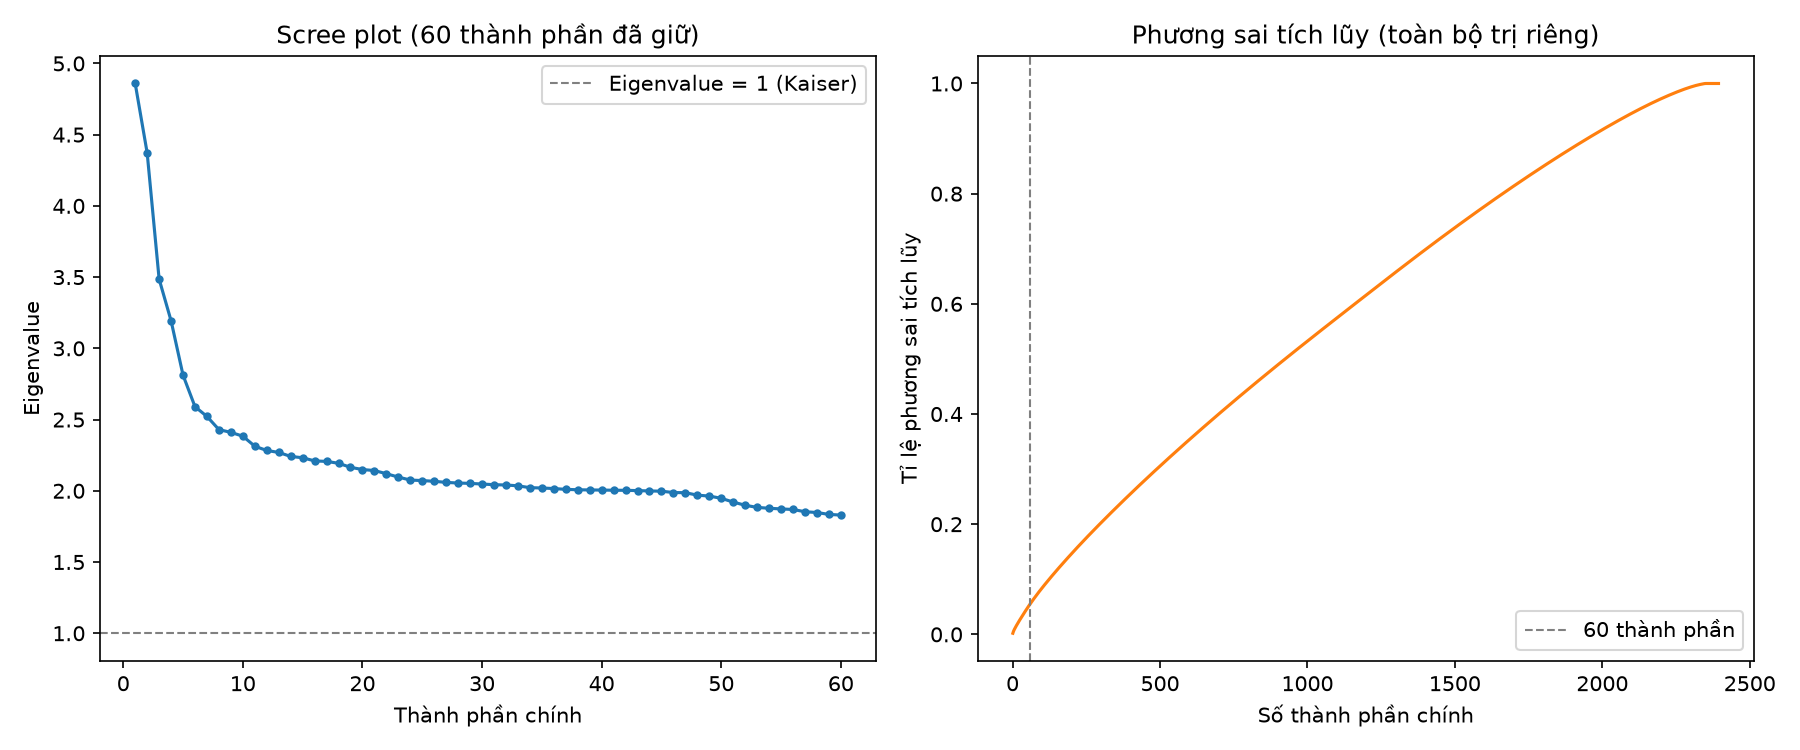

In [8]:
from IPython.display import Image, display
!ls -la output
display(Image("output/eigenvalues.png"))

## Giai đoạn 3: Huấn luyện mô hình

### Bước 07a: Lập trình và tối ưu k-NN (trên dữ liệu chưa chuẩn hoá và đã chuẩn hoá) *(Dũng)*

{'mode': 'chua_chuan_hoa', 'best_k': 5, 'val_macro_f1': 0.38981379928310456, 'test_accuracy': 0.48601228189882056, 'test_macro_f1': 0.3806716221534336, 'test_f1_<30': np.float64(0.13270390768423812), 'test_f1_>30': np.float64(0.4137425927158932), 'test_f1_NO': np.float64(0.5955683660601694)}
{'mode': 'da_chuan_hoa', 'best_k': 9, 'val_macro_f1': 0.39081124725877325, 'test_accuracy': 0.5105273418461839, 'test_macro_f1': 0.3717964243259749, 'test_f1_<30': np.float64(0.07682030728122913), 'test_f1_>30': np.float64(0.4130119483389737), 'test_f1_NO': np.float64(0.6255570173577218)}


,mode,best_k,val_macro_f1,test_accuracy,test_macro_f1,test_f1_<30,test_f1_>30,test_f1_NO
0,chua_chuan_hoa,5,0.3898,0.4860,0.3807,0.1327,0.4137,0.5956
1,da_chuan_hoa,9,0.3908,0.5105,0.3718,0.0768,0.4130,0.6256


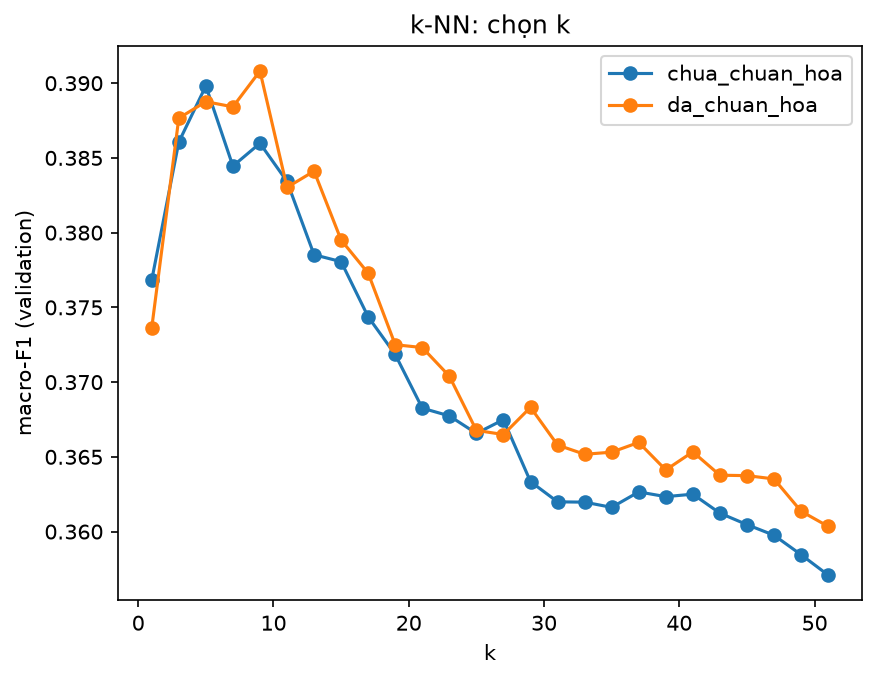

In [9]:
!python ../Dung/src/07a_knn.py
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv("output/knn_results.csv")); display(Image("output/knn_k_curve.png"))

### Bước 07b: Softmax Regression, chưa chuẩn hóa vs đã chuẩn hóa *(Dũng)*


chua_chuan_hoa 0.001 0.0 0.3663 loss cuối: 1.0407
chua_chuan_hoa 0.001 0.001 0.3663 loss cuối: 1.0408
chua_chuan_hoa 0.001 0.01 0.3661 loss cuối: 1.0408
chua_chuan_hoa 0.01 0.0 0.3417 loss cuối: 0.9287
chua_chuan_hoa 0.01 0.001 0.3417 loss cuối: 0.9288
chua_chuan_hoa 0.01 0.01 0.3414 loss cuối: 0.9291
chua_chuan_hoa 0.1 0.0 0.3376 loss cuối: 0.912
chua_chuan_hoa 0.1 0.001 0.3371 loss cuối: 0.9121
chua_chuan_hoa 0.1 0.01 0.3357 loss cuối: 0.913
chua_chuan_hoa 0.5 0.0 0.3415 loss cuối: 0.911
chua_chuan_hoa 0.5 0.001 0.3406 loss cuối: 0.9113
chua_chuan_hoa 0.5 0.01 0.3376 loss cuối: 0.9129
{'mode': 'chua_chuan_hoa', 'lr': 0.001, 'lambda': 0.001, 'val_macro_f1': 0.36628830824966085, 'test_accuracy': 0.5337264840627741, 'test_macro_f1': 0.35946340618056355, 'test_f1_<30': np.float64(0.0016941973739940702), 'test_f1_>30': np.float64(0.4268284276556145), 'test_f1_NO': np.float64(0.6498675935120821)}
da_chuan_hoa 0.001 0.0 0.3293 loss cuối: 1.0507
da_chuan_hoa 0.001 0.001 0.3293 loss cuối: 1.0

,mode,lr,lambda,val_macro_f1,test_accuracy,test_macro_f1,test_f1_<30,test_f1_>30,test_f1_NO
0,chua_chuan_hoa,0.001,0.001,0.3663,0.5337,0.3595,0.0017,0.4268,0.6499
1,da_chuan_hoa,0.500,0.000,0.3397,0.5505,0.3323,0.0008,0.3056,0.6906


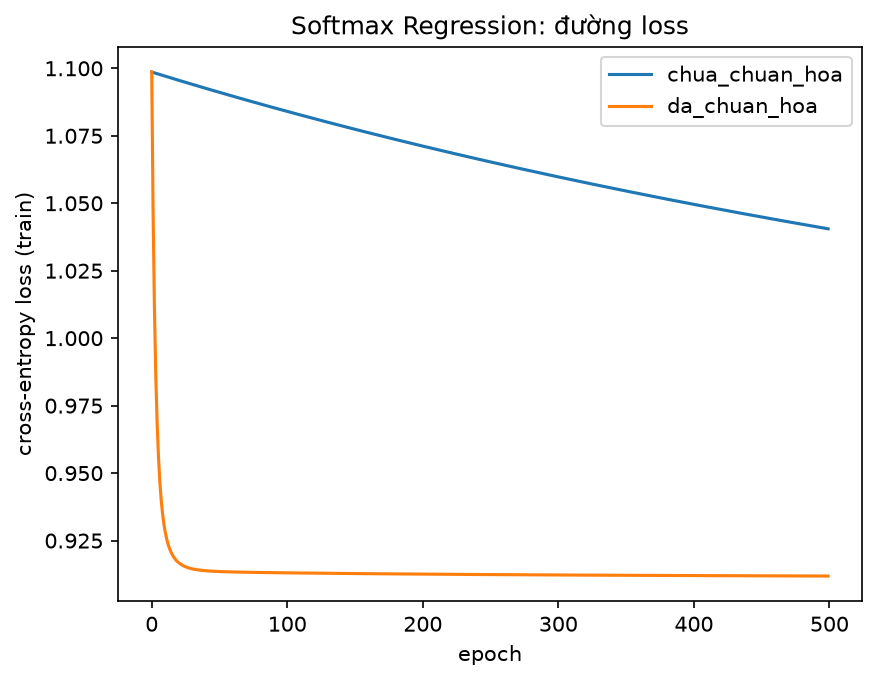

In [10]:
!python ../Dung/src/07b_softmax_regression.py
display(pd.read_csv("output/softmax_results.csv")); display(Image("output/softmax_loss.png"))

### Bước 08a: Decision Tree, tinh chỉnh max_depth chống overfitting *(Sơn)*

y_multi {'label': 'y_multi', 'max_depth': '20', 'min_samples_leaf': 1, 'train_metric': 0.8674974648781816, 'val_metric': 0.3717456938215338}
{'label': 'y_multi', 'max_depth': '20', 'min_samples_leaf': 1, 'train_metric': 0.8674974648781816, 'val_metric': 0.3717456938215338, 'test_accuracy': 0.47027000682327713, 'test_macro_f1': 0.3662140599354702}
y_bin {'label': 'y_bin', 'max_depth': '8', 'min_samples_leaf': 100, 'train_metric': np.float64(0.657968240817542), 'val_metric': np.float64(0.6161587258790626)}
{'label': 'y_bin', 'max_depth': '8', 'min_samples_leaf': 100, 'train_metric': np.float64(0.657968240817542), 'val_metric': np.float64(0.6161587258790626), 'test_accuracy': 0.5875816356370016, 'test_auc': np.float64(0.6139518892500757)}


,label,max_depth,min_samples_leaf,train_metric,val_metric,test_accuracy,test_macro_f1,test_auc
0,y_multi,20,1,0.8675,0.3717,0.4703,0.3662,NaN
1,y_bin,8,100,0.6580,0.6162,0.5876,NaN,0.614


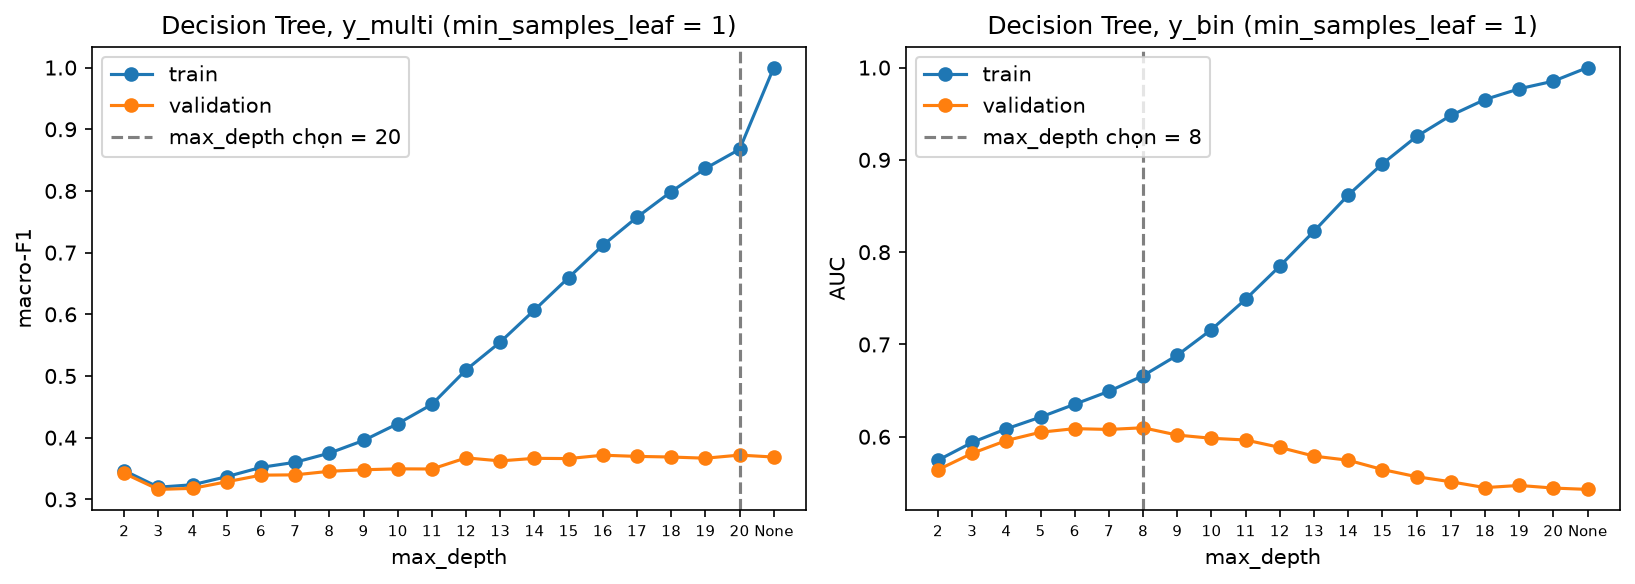

In [11]:
import pandas as pd
from IPython.display import Image, display
!python -u ../Son/src/08a_decision_tree.py
display(pd.read_csv("output/dt_results.csv"))
display(Image("output/dt_depth_curve.png"))

### Bước 08b: Random Forest, tinh chỉnh max_depth và n_estimators *(Sơn)*

y_multi max_depth 4 xong
y_multi max_depth 6 xong
y_multi max_depth 8 xong
y_multi max_depth 10 xong
y_multi max_depth 12 xong
y_multi max_depth 16 xong
y_multi max_depth 20 xong
y_multi max_depth None xong
y_multi {'label': 'y_multi', 'n_estimators': 50, 'max_depth': 'None', 'train_metric': 0.9999876900545427, 'val_metric': 0.36529181056228976}
{'label': 'y_multi', 'n_estimators': 50, 'max_depth': 'None', 'train_metric': 0.9999876900545427, 'val_metric': 0.36529181056228976, 'test_accuracy': 0.5491763329759236, 'test_macro_f1': 0.35872023846889517}
y_bin max_depth 4 xong
y_bin max_depth 6 xong
y_bin max_depth 8 xong
y_bin max_depth 10 xong
y_bin max_depth 12 xong
y_bin max_depth 16 xong
y_bin max_depth 20 xong
y_bin max_depth None xong
y_bin {'label': 'y_bin', 'n_estimators': 400, 'max_depth': '20', 'train_metric': np.float64(0.999997818157489), 'val_metric': np.float64(0.6542047914977592)}
{'label': 'y_bin', 'n_estimators': 400, 'max_depth': '20', 'train_metric': np.float64(0.9999978

,label,n_estimators,max_depth,train_metric,val_metric,test_accuracy,test_macro_f1,test_auc
0,y_multi,50,NaN,1.0,0.3653,0.5492,0.3587,NaN
1,y_bin,400,20.0,1.0,0.6542,0.6085,NaN,0.6537


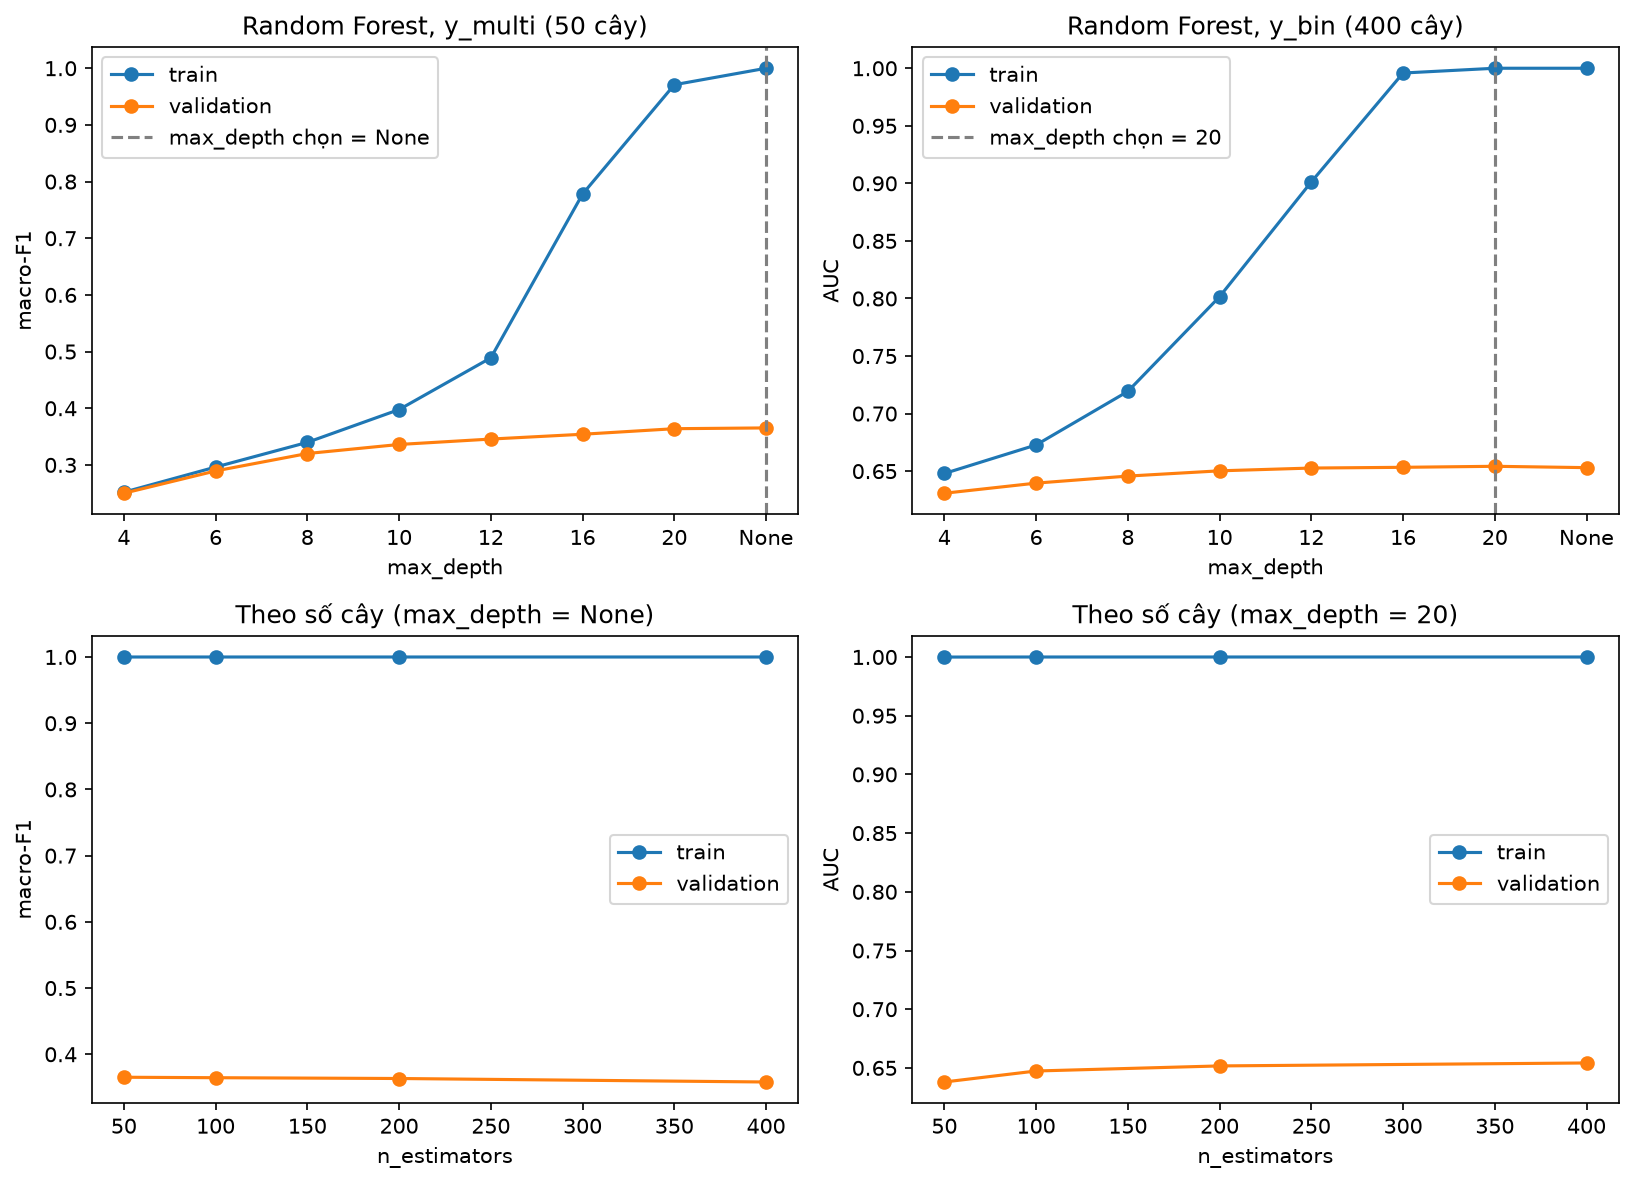

In [12]:
!python -u ../Son/src/08b_random_forest.py
display(pd.read_csv("output/rf_results.csv"))
display(Image("output/rf_depth_curve.png"))

### Bước 09a: Deep Neural Network / MLP (120-60-20, ReLU) *(Chiến)*


=== y_multi: quét 12 cấu hình, độ đo macro_f1 ===
  label  alpha    lr  train    val  n_iter
y_multi 0.0000 0.001 0.3720 0.3606      16
y_multi 0.0001 0.001 0.3737 0.3616      16
y_multi 0.0010 0.001 0.3865 0.3708      17
y_multi 0.0100 0.001 0.3759 0.3644      16
y_multi 0.1000 0.001 0.3881 0.3673      35
y_multi 1.0000 0.001 0.3655 0.3582      32
y_multi 0.0000 0.010 0.3797 0.3683      28
y_multi 0.0001 0.010 0.3892 0.3753      25
y_multi 0.0010 0.010 0.3910 0.3724      22
y_multi 0.0100 0.010 0.3868 0.3750      32
y_multi 0.1000 0.010 0.3753 0.3698      18
y_multi 1.0000 0.010 0.3493 0.3481      20
Chọn alpha=0.0001, lr=0.01 (val macro_f1 = 0.3753)

=== y_bin: quét 12 cấu hình, độ đo auc ===
label  alpha    lr  train    val  n_iter
y_bin 0.0000 0.001 0.6989 0.6650      19
y_bin 0.0001 0.001 0.6996 0.6635      19
y_bin 0.0010 0.001 0.7272 0.6624      28
y_bin 0.0100 0.001 0.7240 0.6632      28
y_bin 0.1000 0.001 0.6989 0.6706      28
y_bin 1.0000 0.001 0.6575 0.6515      28
y_bin 0.

,label,alpha,learning_rate_init,train_macro_f1,val_macro_f1,test_accuracy,test_macro_f1,train_auc,val_auc,test_auc
0,y_multi,0.0001,0.010,0.3892,0.3753,0.5647,0.3591,NaN,NaN,NaN
1,y_bin,0.1000,0.001,NaN,NaN,0.6212,NaN,0.6989,0.6706,0.6683


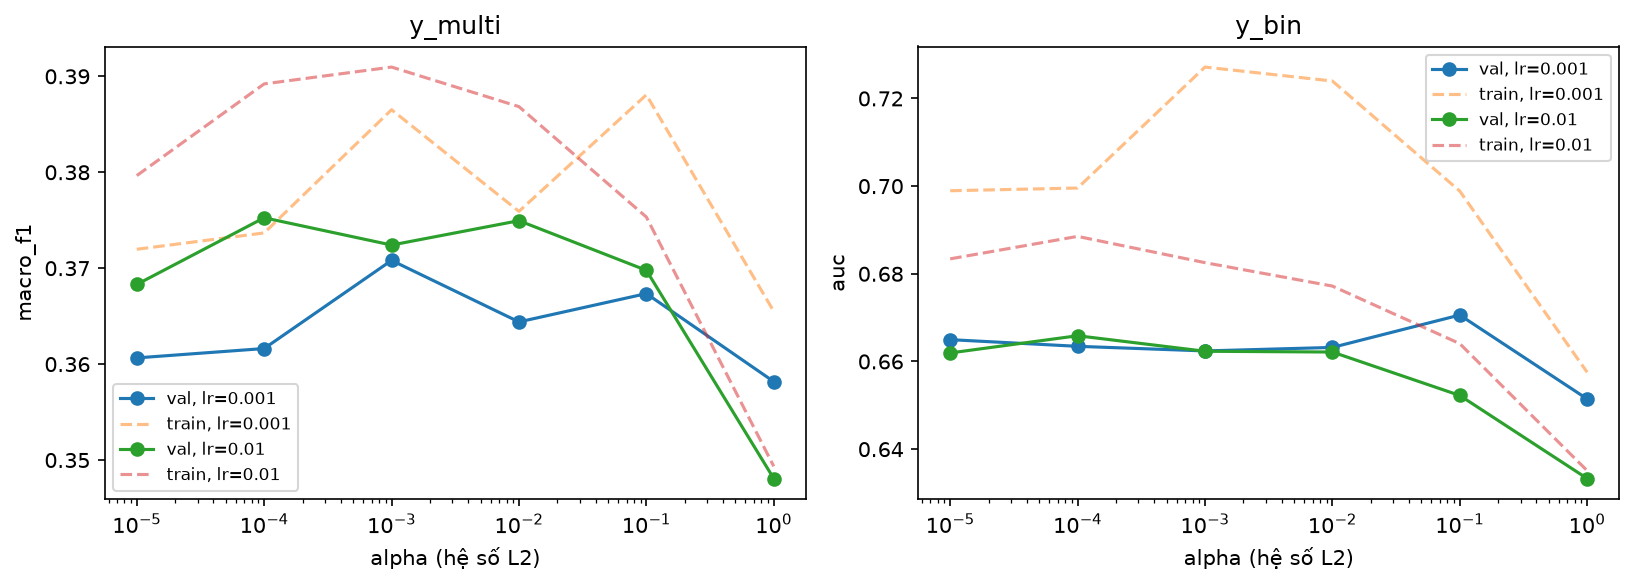

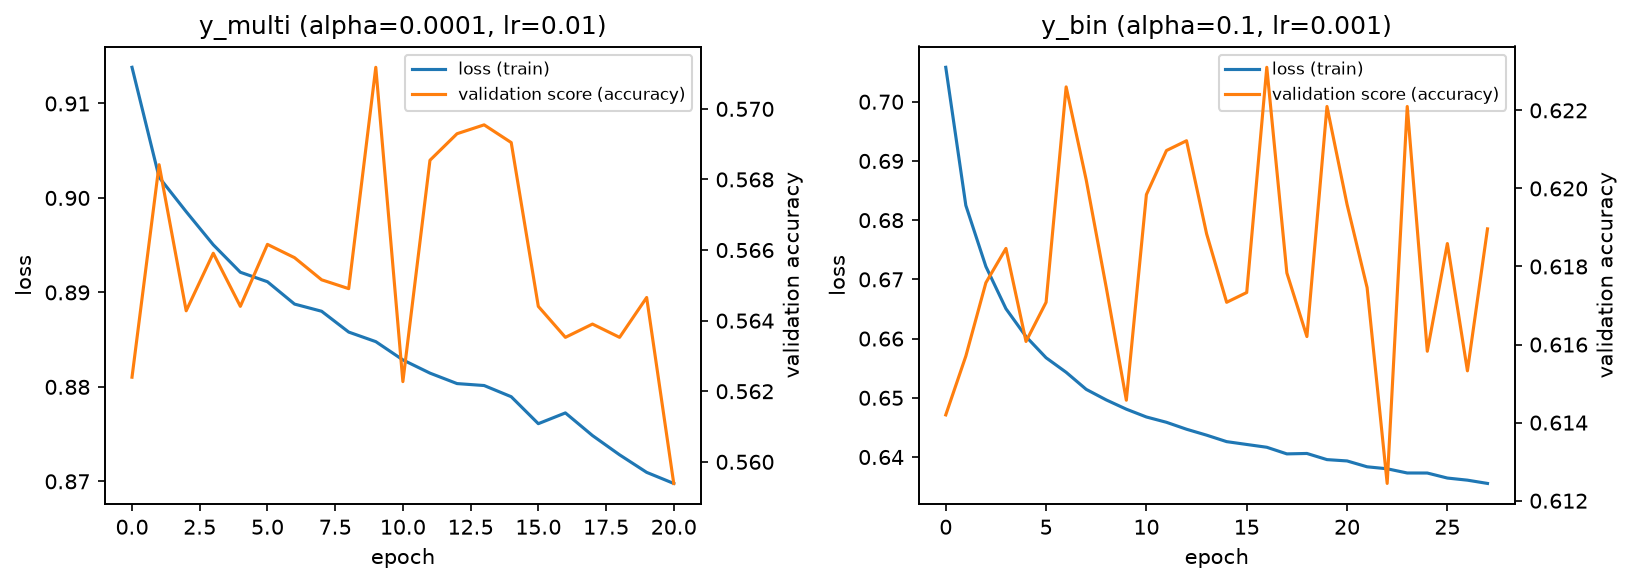

In [13]:
!python -u ../Chien/src/09a_mlp.py
display(pd.read_csv("output/mlp_results.csv"))
display(Image("output/mlp_alpha_curve.png"))
display(Image("output/mlp_loss.png"))

### Bước 09b: Aggregate Ensemble theo trọng số AUC-ROC *(Chiến)*

In [14]:
!python -u ../Chien/src/09b_ensemble.py
display(pd.read_csv("output/ensemble_weights.csv"))
display(pd.read_csv("output/ensemble_results.csv"))

/home/hdung274520/Study/261/Máy học Cơ bản và Ứng dụng/Dung/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/hdung274520/Study/261/Máy học Cơ bản và Ứng dụng/Dung/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
     auc_val   w_auc  w_equal  w_auc_tru_0.5
dt    0.6162  0.2395     0.25         0.2028
rf    0.6542  0.2543     0.25         0.2693
mlp   0.6706  0.2607     0.25         0.2979
lr    0.6317  0.2456     0.25         0.2300

                         test_auc  test_accuracy  test_recall  test_f1
dt                        0.6140         0.5876       0.5119   0.5372
rf                        0.6537         0.6085       0.4848   0.5367
mlp                       0.6683         0.6212       0.5950   0.5950
lr                        0.6344         0.5992       0.4631   0.51

,model,auc_val,w_auc,w_equal,w_auc_tru_0.5
0,dt,0.6162,0.2395,0.25,0.2028
1,rf,0.6542,0.2543,0.25,0.2693
2,mlp,0.6706,0.2607,0.25,0.2979
3,lr,0.6317,0.2456,0.25,0.2300


,model,test_auc,test_accuracy,test_recall,test_f1
0,dt,0.6140,0.5876,0.5119,0.5372
1,rf,0.6537,0.6085,0.4848,0.5367
2,mlp,0.6683,0.6212,0.5950,0.5950
3,lr,0.6344,0.5992,0.4631,0.5194
4,ensemble_w_auc,0.6644,0.6192,0.5171,0.5595
5,ensemble_trung_binh,0.6639,0.6188,0.5152,0.5584
6,ensemble_w_auc_tru_0.5,0.6662,0.6198,0.5212,0.5618


## Giai đoạn 4: Đánh giá tổng hợp

### Bước 10: Test Accuracy multi-class, ma trận nhầm lẫn *(Dũng)*


             model           data  test_accuracy  macro_f1  baseline_majority
              k-NN Chưa chuẩn hóa         0.4860    0.3807             0.5323
              k-NN   Đã chuẩn hóa         0.5105    0.3718             0.5323
Softmax Regression Chưa chuẩn hóa         0.5337    0.3595             0.5323
Softmax Regression   Đã chuẩn hóa         0.5505    0.3323             0.5323


,model,data,test_accuracy,macro_f1,baseline_majority
0,k-NN,Chưa chuẩn hóa,0.4860,0.3807,0.5323
1,k-NN,Đã chuẩn hóa,0.5105,0.3718,0.5323
2,Softmax Regression,Chưa chuẩn hóa,0.5337,0.3595,0.5323
3,Softmax Regression,Đã chuẩn hóa,0.5505,0.3323,0.5323


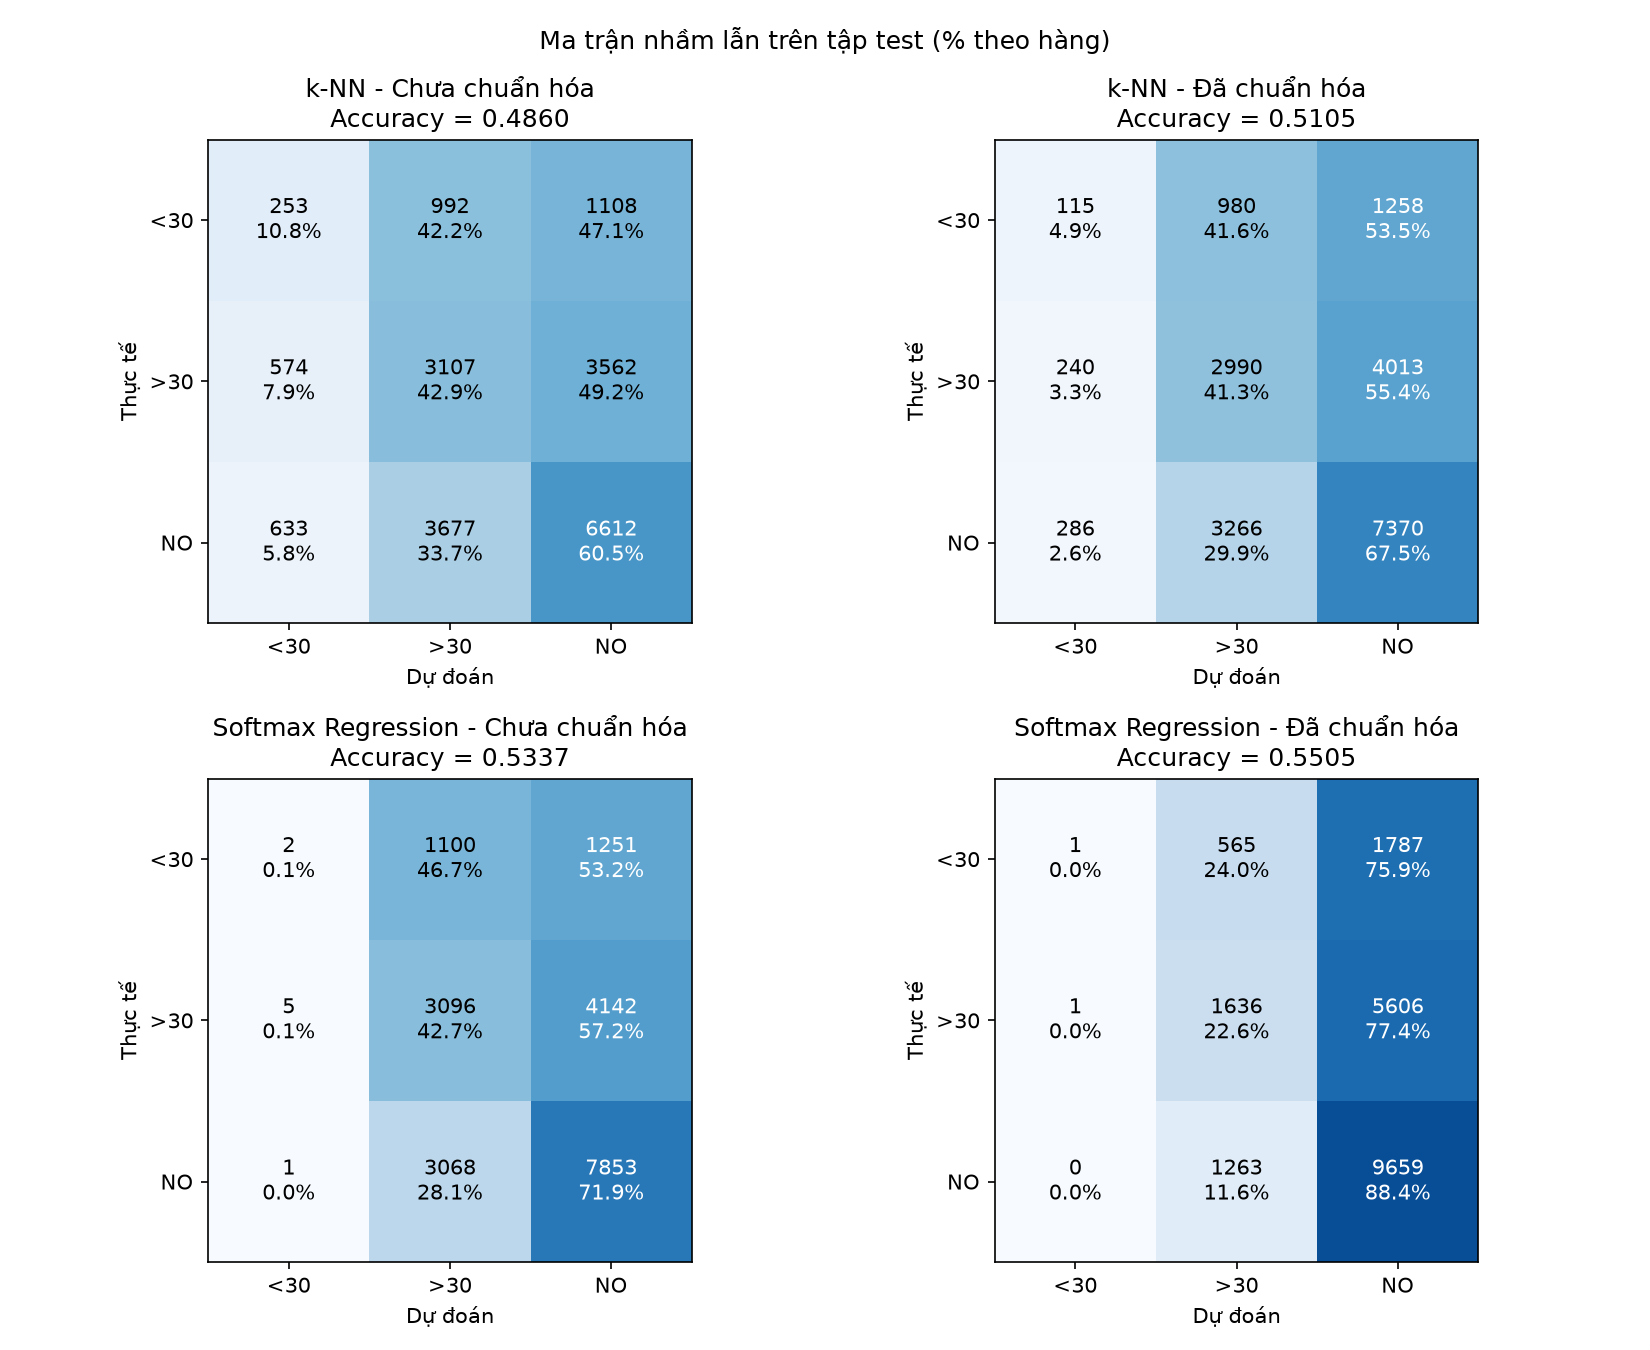

In [15]:
import pandas as pd
from IPython.display import Image, display
!python ../Dung/src/10_evaluation.py
display(pd.read_csv("output/accuracy_summary.csv"))
display(Image("output/confusion_matrices.png"))

### Bước 11: Test Accuracy bài toán nhị phân, đường cong ROC/AUC *(Sơn)*

                  model  test_accuracy    auc  precision  recall     f1  baseline_majority
          Decision Tree         0.5876 0.6140     0.5652  0.5119 0.5372             0.5323
Ensemble (trọng số AUC)         0.6192 0.6644     0.6095  0.5171 0.5595             0.5323
    Logistic Regression         0.5992 0.6344     0.5913  0.4631 0.5194             0.5323
                    MLP         0.6212 0.6683     0.5950  0.5950 0.5950             0.5323
          Random Forest         0.6085 0.6537     0.6010  0.4848 0.5367             0.5323


,model,test_accuracy,auc,precision,recall,f1,baseline_majority
0,Decision Tree,0.5876,0.6140,0.5652,0.5119,0.5372,0.5323
1,Ensemble (trọng số AUC),0.6192,0.6644,0.6095,0.5171,0.5595,0.5323
2,Logistic Regression,0.5992,0.6344,0.5913,0.4631,0.5194,0.5323
3,MLP,0.6212,0.6683,0.5950,0.5950,0.5950,0.5323
4,Random Forest,0.6085,0.6537,0.6010,0.4848,0.5367,0.5323


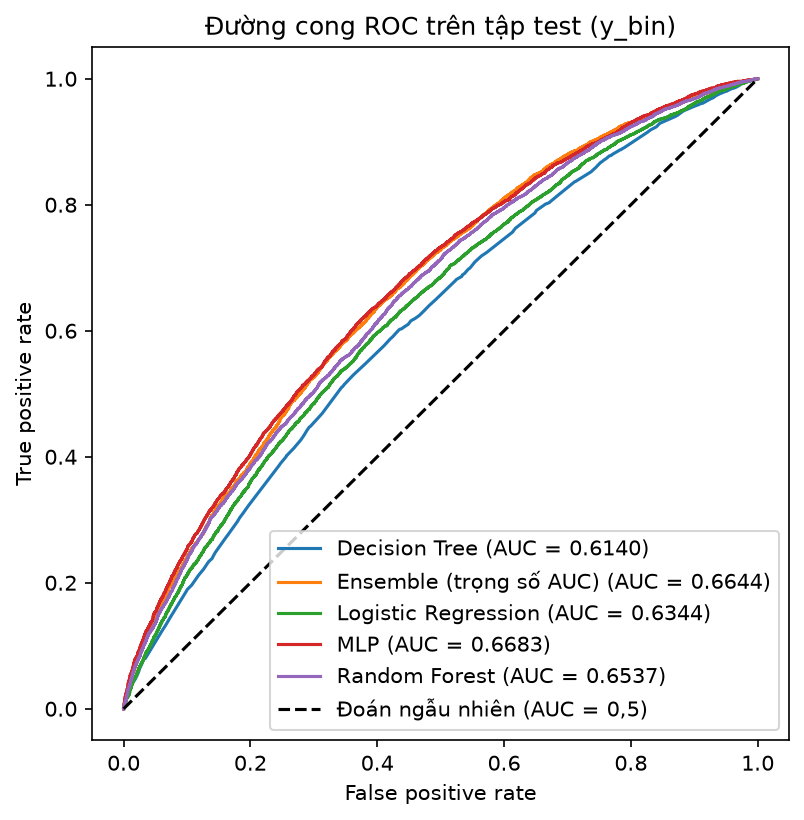

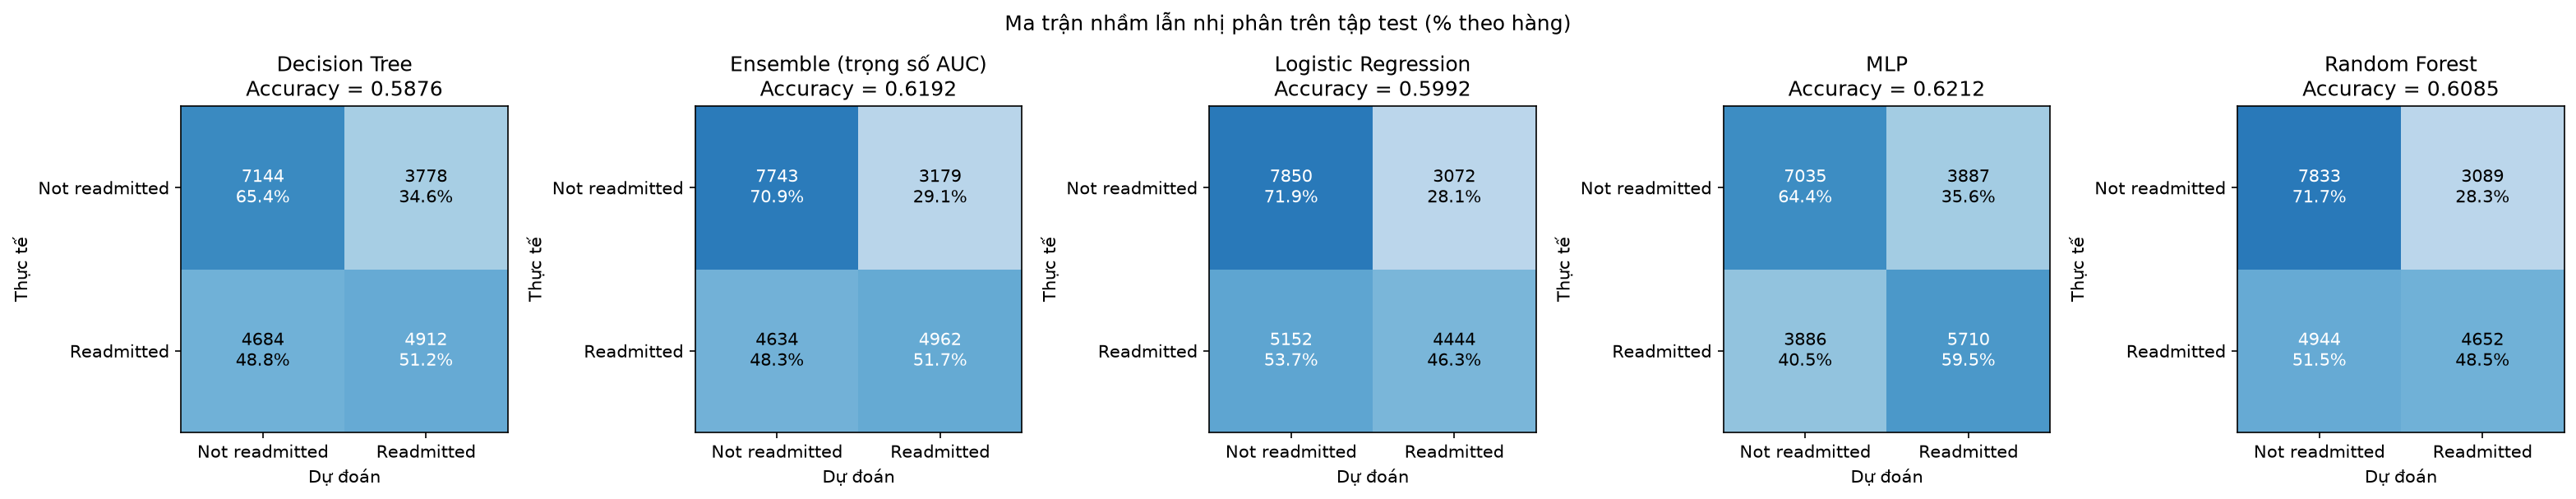

In [16]:
!python -u ../Son/src/11_binary_evaluation.py
display(pd.read_csv("output/binary_summary.csv"))
display(Image("output/roc_curves.png"))
display(Image("output/confusion_binary.png"))

### Bước 12: Ảnh hưởng của Class Imbalance; Random Forest trên One-Hot chưa PCA *(Chiến)*

RF One-Hot max_depth 8 val AUC 0.678
RF One-Hot max_depth 12 val AUC 0.6823
RF One-Hot max_depth 16 val AUC 0.6853
RF One-Hot max_depth 20 val AUC 0.6875
RF One-Hot max_depth None val AUC 0.6915
imbalance_distribution


,tap,nhan,lop,so_mau,ty_le
0,train,y_multi,<30,8897,0.1116
1,train,y_multi,>30,27930,0.3503
2,train,y_multi,NO,42899,0.5381
3,train,y_bin,0,42899,0.5381
4,train,y_bin,1,36827,0.4619
5,test,y_multi,<30,2353,0.1147
6,test,y_multi,>30,7243,0.3530
7,test,y_multi,NO,10922,0.5323
8,test,y_bin,0,10922,0.5323
9,test,y_bin,1,9596,0.4677


imbalance_rf_multi


,mo_hinh,test_accuracy,macro_f1,recall_<30,recall_>30,recall_NO,so_lan_doan_<30
0,RF không class_weight,0.5492,0.3587,0.0076,0.3305,0.8108,59
1,RF class_weight=balanced,0.5502,0.3542,0.0089,0.2993,0.8331,59
2,Mốc: luôn đoán NO,0.5323,0.2316,0.0000,0.0000,1.0000,0


imbalance_threshold


,ngưỡng,t,test_accuracy,precision,recall,f1,test_auc
0,"Ngưỡng 0,5",0.50,0.6085,0.6010,0.4848,0.5367,0.6537
1,Ngưỡng chọn trên validation (0.32),0.32,0.5277,0.4974,0.9408,0.6507,0.6537


rf_raw_results


,du_lieu,n_estimators,max_depth,val_auc,test_accuracy,test_auc
0,One-Hot (chưa PCA),200,NaN,0.6915,0.6413,0.6957
1,PCA 60 chiều (Task 1),400,20.0,0.6542,0.6085,0.6537


,thuoc_tinh,mdi,permutation_giam_auc
0,diag_1,0.141070,0.007428
1,diag_2,0.136895,0.005105
2,diag_3,0.136686,0.005264
3,medical_specialty,0.048579,0.003776
4,age,0.048518,0.004179
5,num_lab_procedures,0.048215,0.001224
6,discharge_disposition_id,0.046929,0.024956
7,num_medications,0.045159,0.002713
8,number_inpatient,0.038187,0.046978
9,time_in_hospital,0.034497,0.000178


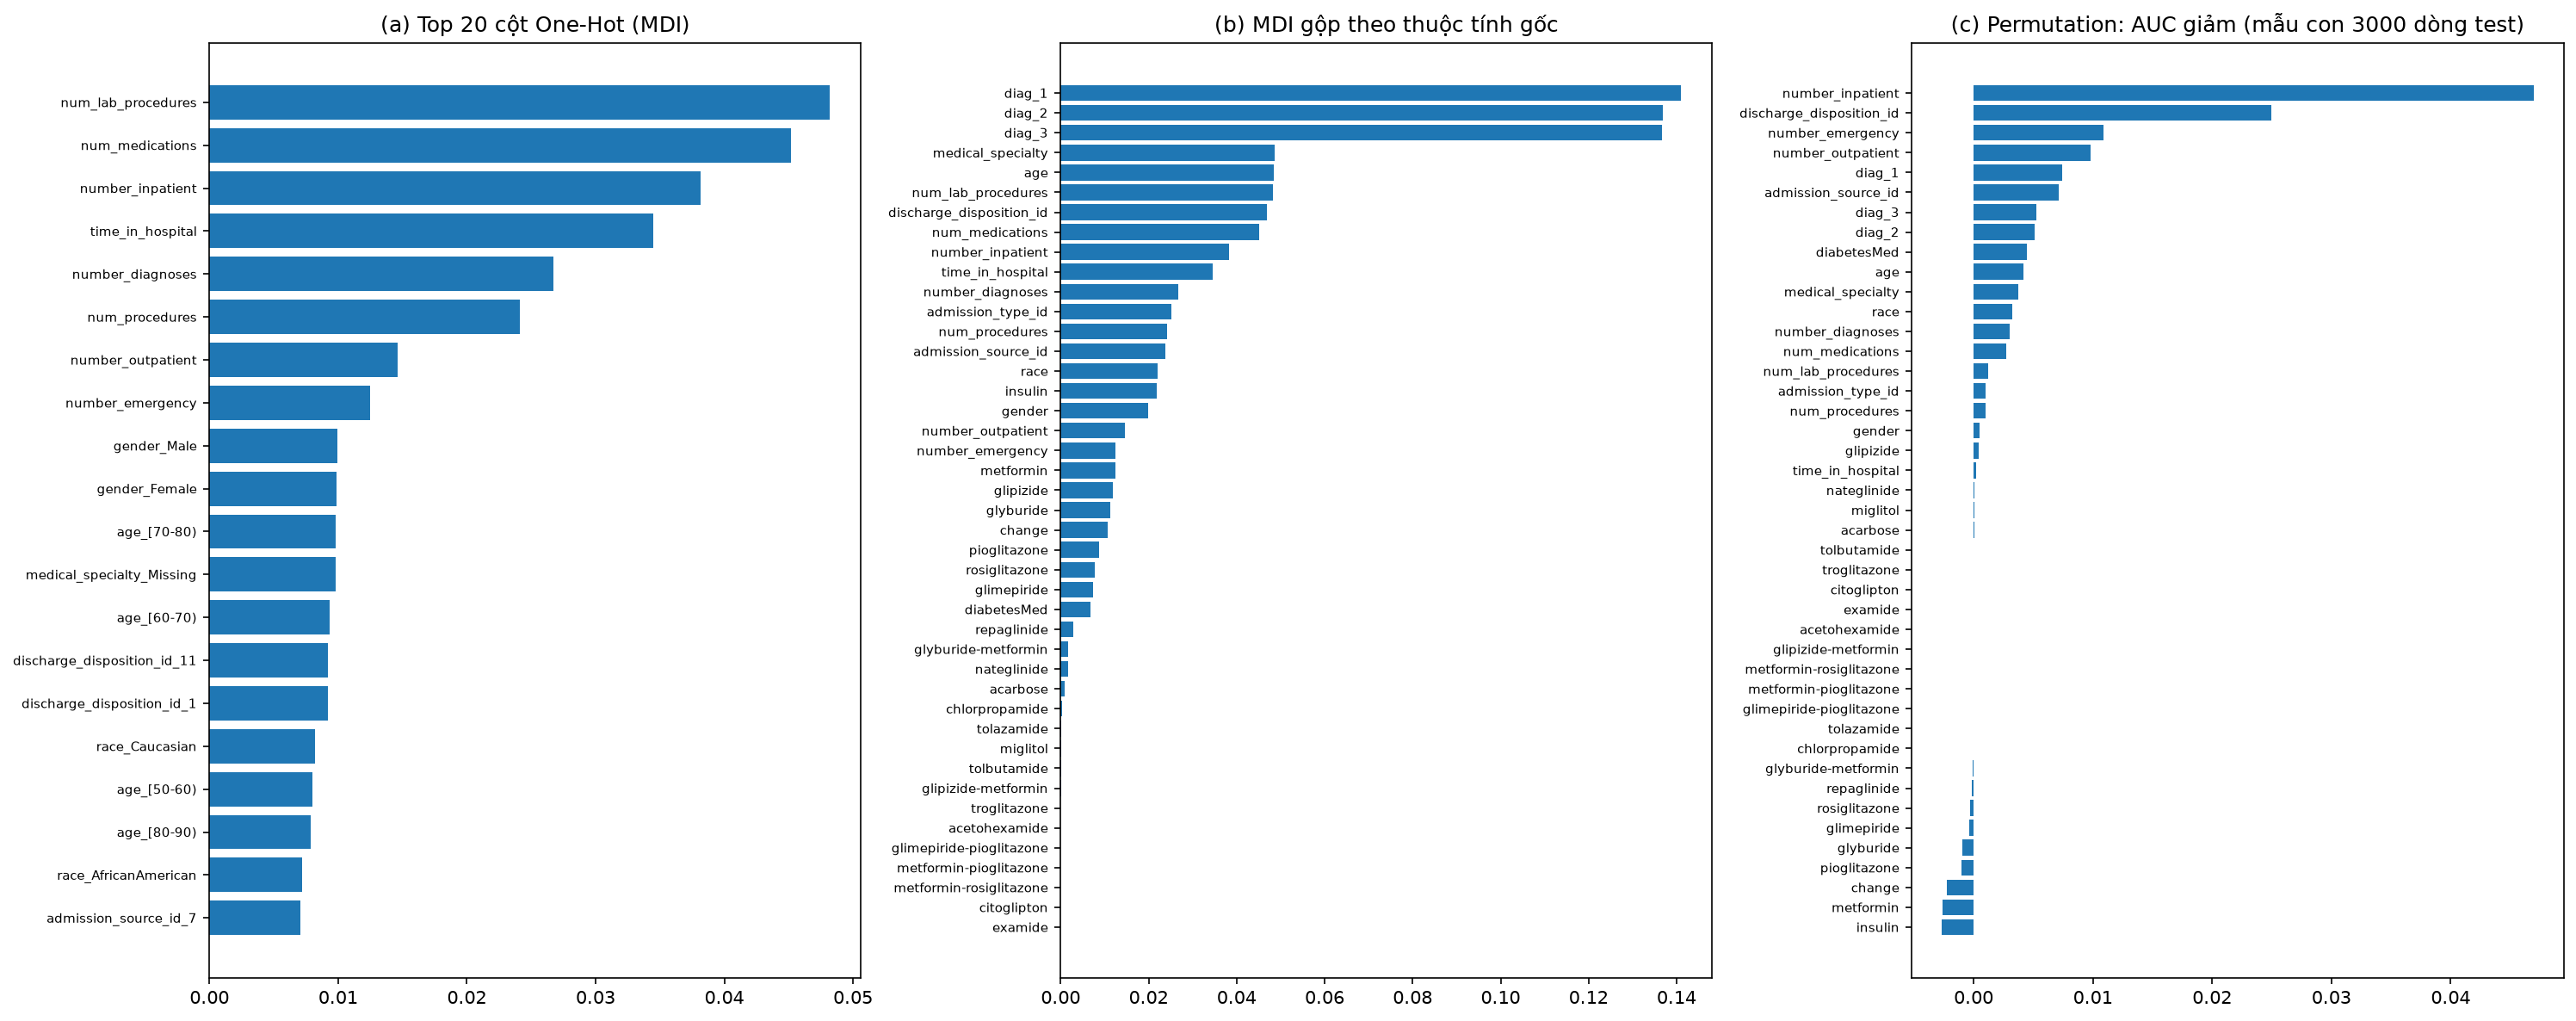

In [17]:
!python -u ../Chien/src/12_imbalance_and_rf_raw.py
for f in ["imbalance_distribution", "imbalance_rf_multi", "imbalance_threshold", "rf_raw_results"]:
    print(f); display(pd.read_csv(f"output/{f}.csv"))
display(pd.read_csv("output/rf_raw_importance_orig.csv").head(15))
display(Image("output/rf_raw_importance.png"))